In [ ]:
!git clone https://github.com/AndreFGard/Yolo-Depth-Underwater.git
%cd Yolo-Depth-Underwater
!git checkout flsea-eval
!pip -q install ultralytics "transformers>=4.45" tqdm
import os; os.environ["PYTHONPATH"] = "/content/Yolo-Depth-Underwater/src"

Cloning into 'Yolo-Depth-Underwater'...
remote: Enumerating objects: 216, done.
remote: Counting objects: 100% (216/216), done.
remote: Compressing objects: 100% (116/116), done.
remote: Total 216 (delta 106), reused 178 (delta 68), pack-reused 0 (from 0)
Receiving objects: 100% (216/216), 212.60 KiB | 7.59 MiB/s, done.
Resolving deltas: 100% (106/106), done.
/content/Yolo-Depth-Underwater
branch 'flsea-eval' set up to track 'origin/flsea-eval'.
Switched to a new branch 'flsea-eval'


In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!find /content/drive/MyDrive -name "data.yaml" 2>/dev/null | head

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip -q install gdown
!gdown 1eJW9-EN6nTe_sKSzO6XxkoJPNwhoGBN9 -O /content/usod.zip
!ls -la /content/usod.zip

Downloading...
From (original): https://drive.google.com/uc?id=1eJW9-EN6nTe_sKSzO6XxkoJPNwhoGBN9
From (redirected): https://drive.google.com/uc?id=1eJW9-EN6nTe_sKSzO6XxkoJPNwhoGBN9&confirm=t&uuid=47a3500b-62f9-4142-a259-046578bbab26
To: /content/usod.zip
100% 6.02G/6.02G [01:26<00:00, 69.4MB/s]
-rw-r--r-- 1 root root 6016263386 Oct 19 00:21 /content/usod.zip


In [ ]:
!unzip -q /content/usod.zip -d /content/usod_zip
!find /content/usod_zip -maxdepth 3 | head -40
!find /content/usod_zip -name "data.yaml"

/content/usod_zip
/content/usod_zip/usod10k_new_script
/content/usod_zip/usod10k_new_script/images
/content/usod_zip/usod10k_new_script/images/val
/content/usod_zip/usod10k_new_script/images/test
/content/usod_zip/usod10k_new_script/images/train
/content/usod_zip/usod10k_new_script/annotations
/content/usod_zip/usod10k_new_script/annotations/annotations.json
/content/usod_zip/usod10k_new_script/depth
/content/usod_zip/usod10k_new_script/depth/val
/content/usod_zip/usod10k_new_script/depth/test
/content/usod_zip/usod10k_new_script/depth/train
/content/usod_zip/usod10k_new_script/data.yaml
/content/usod_zip/usod10k_new_script/data.yaml


In [ ]:
%cd /content/Yolo-Depth-Underwater
!cat /content/usod_zip/usod10k_new_script/data.yaml
!sed -i 's|^path: .*|path: /content/usod_zip/usod10k_new_script|' /content/usod_zip/usod10k_new_script/data.yaml
!head -6 /content/usod_zip/usod10k_new_script/data.yaml

/content/Yolo-Depth-Underwater
# USOD10k depth dataset — RGB + relative depth
# Built by scripts/convert_usd10k_to_coco.py.

path: datasets/usod10k_new_script
train: images/train
val: images/val
test: images/test

nc: 1
names:
  0: depth

depth_scale: 1000

# Semantics: relative depth (higher = farther), converted from USOD10k's
# DPT disparity maps via depth_rel = eps/(d + eps), d = raw/65535.
# eps = 0.25, uint16 range [13107, 65535]; 0 = invalid (never emitted).
# Max far/near ratio ≈ 5. NOT metric depth.
# Use scale-aligned metrics only (median-aligned delta1).

source:
  name: USOD10k
  url: https://github.com/DCCover/USOD10k
  gt_nature: DPT monocular-network pseudo-depth (per-image min-max normalized
    disparity), not sensor-captured. Cross-image comparisons are meaningless.
  splits: {train: 7178, val: 2051, test: 1026}
# USOD10k depth dataset — RGB + relative depth
# Built by scripts/convert_usd10k_to_coco.py.

path: /content/usod_zip/usod10k_new_script
train: images/train
v

In [ ]:
import os; os.environ["PYTHONPATH"] = "/content/Yolo-Depth-Underwater/src"
!python scripts/check_dataset.py /content/usod_zip/usod10k_new_script/data.yaml --splits test

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
# USOD10k depth dataset — RGB + relative depth
# Built by scripts/convert_usd10k_to_coco.py.

path: /content/usod_zip/usod10k_new_script
train: images/train
val: images/val
test: images/test

nc: 1
names:
  0: depth

depth_scale: 1000

# Semantics: relative depth (higher = farther), converted from USOD10k's
# DPT disparity maps via depth_rel = eps/(d + eps), d = raw/65535.
# eps = 0.25, uint16 range [13107, 65535]; 0 = invalid (never emitted).
# Max far/near ratio ≈ 5. NOT metric depth.
# Use scale-aligned metrics only (median-aligned delta1).

source:
  name: USOD10k
  url: https://github.com/DCCover/USOD10k
  gt_nature: DPT monocular-network pseudo-depth (per-image min-max normalized
    disparity

In [ ]:
%%writefile /content/Yolo-Depth-Underwater/scripts/predict_usod_depth_anything.py
#!/usr/bin/env python3
"""Roda o Depth Anything V2 nas imagens do USOD10K (formato COCO-depth do repo) e salva
os mapas previstos.

Saída, por imagem:
  <out>/raw/<split>/<nome>.npy  float32, DISPARIDADE do Depth Anything V2 (maior = mais
                                perto), sem normalização nem quantização.
  <out>/rel/<split>/<nome>.png  uint16, PROFUNDIDADE RELATIVA no mesmo formato dos labels
                                do USOD10K convertidos pelo repo (maior = mais longe):
                                disparidade com min-max por imagem, d em [0, 1], e
                                depth_rel = eps / (d + eps), gravado como depth_rel * 65535
                                (mesma fórmula de scripts/convert_usd10k_to_coco.py).
Não é metros: use o alinhamento por imagem (escala + deslocamento) para avaliar.
"""

import argparse
from pathlib import Path

import cv2
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from tqdm import tqdm


def disparity_to_relative_depth_u16(disp, eps=0.25):
    """Disparidade do modelo -> profundidade relativa uint16, como nos labels do USOD10K.

    min-max por imagem (como a disparidade original dos labels) e depth_rel = eps/(d+eps).
    """
    disp = np.asarray(disp, dtype=np.float64)
    lo, hi = float(disp.min()), float(disp.max())
    d = (disp - lo) / max(hi - lo, 1e-9)
    return np.rint(eps / (d + eps) * 65535.0).astype(np.uint16)


def run(model, image_paths_by_split, depth_paths_by_split, out_dir, eps=0.25, preview=0):
    """Salva .npy (disparidade) e .png (profundidade relativa) por imagem.

    Devolve {split: n_imagens}. ``preview``: nº de figuras de conferência.
    """
    out_dir = Path(out_dir)
    counts = {}
    for split, paths in image_paths_by_split.items():
        dest = out_dir / "raw" / split
        dest_rel = out_dir / "rel" / split
        dest.mkdir(parents=True, exist_ok=True)
        dest_rel.mkdir(parents=True, exist_ok=True)
        gts = depth_paths_by_split.get(split)
        for i, path in enumerate(tqdm(paths, desc=split)):
            image = cv2.imread(str(path))  # BGR uint8: serve para RGB de 8 bits
            if image is None:
                raise FileNotFoundError(path)
            pred = np.asarray(next(iter(model.predict(iter([image])))), dtype=np.float32).squeeze()
            np.save(dest / f"{Path(path).stem}.npy", pred)
            rel = disparity_to_relative_depth_u16(pred, eps)
            Image.fromarray(rel).save(dest_rel / Path(path).name, format="PNG")
            if i < preview:
                fig, ax = plt.subplots(1, 3 if gts else 2, figsize=(14 if gts else 9.5, 3.8))
                ax[0].imshow(image[..., ::-1]); ax[0].set_title("RGB")
                ax[1].imshow(rel, cmap="magma_r", vmin=0, vmax=65535)
                ax[1].set_title("Depth Anything V2 S (prof. relativa)")
                if gts:
                    gt = np.asarray(Image.open(gts[i]), dtype=np.float32)
                    ax[2].imshow(gt, cmap="magma_r", vmin=0, vmax=65535)
                    ax[2].set_title("USOD10K (label, prof. relativa)")
                for a in ax:
                    a.axis("off")
                fig.tight_layout()
                fig.savefig(dest / f"preview_{Path(path).stem}.png", dpi=130, bbox_inches="tight")
                plt.close(fig)
        counts[split] = len(paths)
    return counts


def main():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--data-yaml", type=Path, required=True)
    p.add_argument("--splits", nargs="+", default=["test"], choices=["train", "val", "test"])
    p.add_argument("--out", type=Path, default=Path("preds_da_usod"))
    p.add_argument("--variant", default="small")
    p.add_argument("--eps", type=float, default=0.25, help="mesmo eps da conversão dos labels")
    p.add_argument("--preview", type=int, default=0)
    args = p.parse_args()

    from yolo_depth_underwater.dataset import DepthDataset
    from yolo_depth_underwater.depth_anything_model import DepthAnythingV2Model
    from yolo_depth_underwater.split import Split

    ds = DepthDataset(args.data_yaml)
    images = {s: ds.image_paths(Split(s)) for s in args.splits}
    depths = {s: ds.depth_paths(Split(s)) for s in args.splits}
    print({s: len(v) for s, v in images.items()})
    counts = run(DepthAnythingV2Model(variant=args.variant), images, depths, args.out, args.eps, args.preview)
    print("pronto:", counts, "->", args.out)


if __name__ == "__main__":
    main()

Writing /content/Yolo-Depth-Underwater/scripts/predict_usod_depth_anything.py


In [ ]:
!ls -la /content/Yolo-Depth-Underwater/scripts/predict_usod_depth_anything.py
%cd /content/Yolo-Depth-Underwater
!python scripts/predict_usod_depth_anything.py --data-yaml /content/usod_zip/usod10k_new_script/data.yaml --splits test --out preds_da_usod --preview 6

-rw-r--r-- 1 root root 4606 Nov 21 19:10 /content/Yolo-Depth-Underwater/scripts/predict_usod_depth_anything.py
/content/Yolo-Depth-Underwater
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5140.1±1208.7 MB/s, size: 454.4 KB)
test: Scanning /content/usod_zip/usod10k_new_script/depth/test.cache... 1026 images, 0 missing depth, 0 corrupt: 100% ━━━━━━━━━━━━ 1026/1026 204.9Mit/s 0.0s
WARNING ⚠️ cache='ram' may produce non-deterministic training results. Consider cache='disk' as a deterministic alternative if your disk space allows.
test: Caching images (0.9GB RAM): 100% ━━━━━━━━━━━━ 1026/1026 131.2it/s 7.8s
{'test': 1026}
Starting Depth Anything V2: depth-anything/Depth-Anything-V2-Small-hf
preprocessor_config.json: 100% 775/775 [00:00<00:00, 2.42MB/s]
config.json: 100% 950/950 [00:00<00:00, 3.28MB/s]

model.safetensors: downloading bytes:  91% 90.2M/99.2M [00:01<00:00, 127MB/s, 7.07MB/s  ]
model.safetensors: downloading bytes: 100% 94.1M/94.1M [00:01<00:00, 68.6MB/s, 8.93MB/s  ]
model.

1026 1026
float32 (480, 640) -0.04449435 5.202452 | uint16 (480, 640) 13107 65535
correlação com o label: média 0.884 | fração positiva 1.0


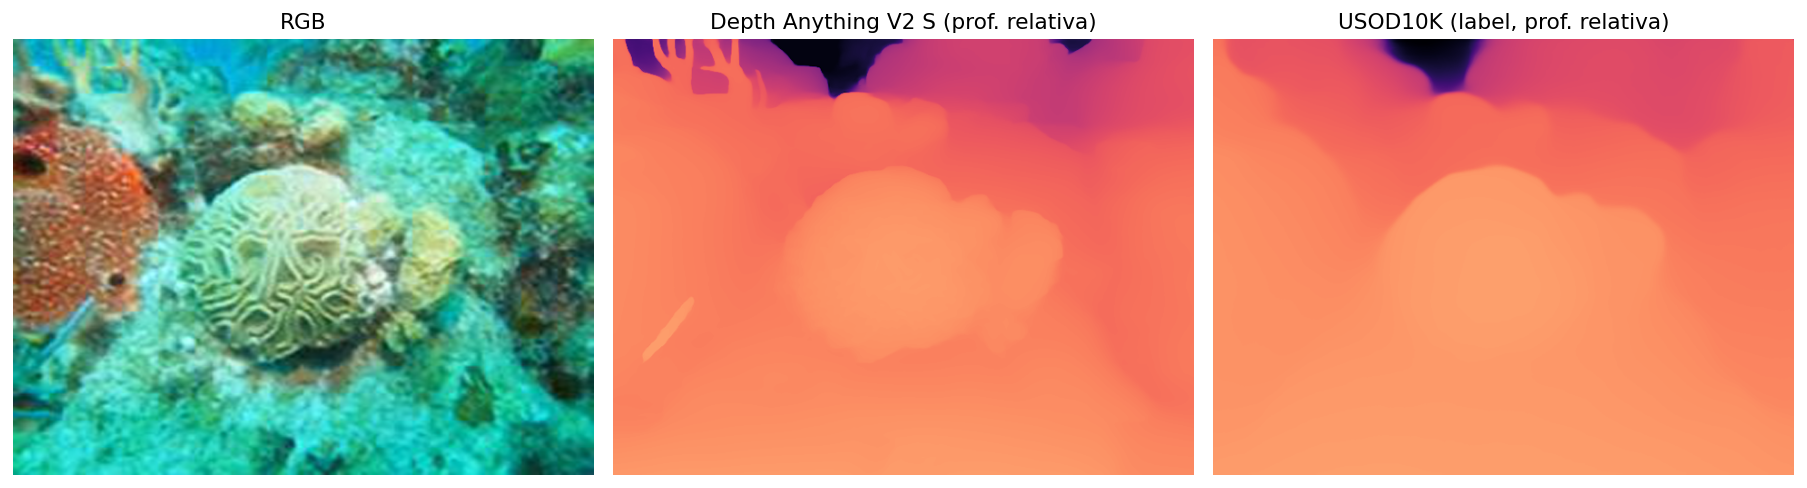

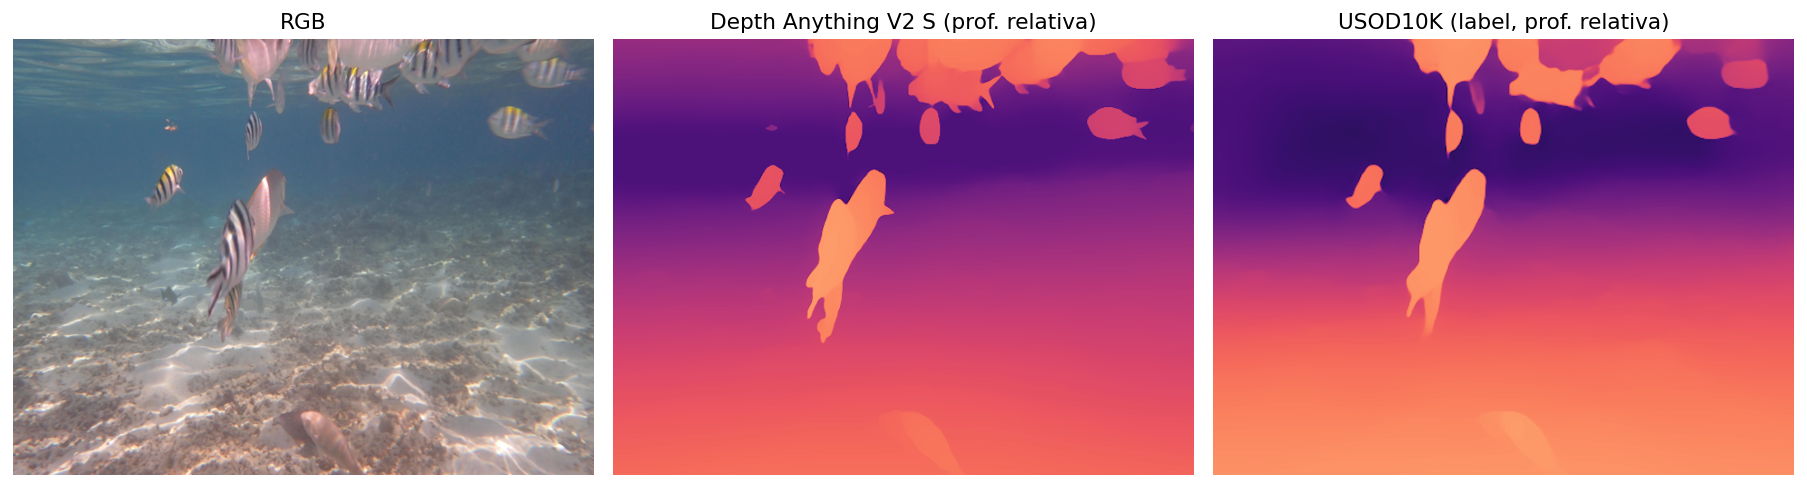

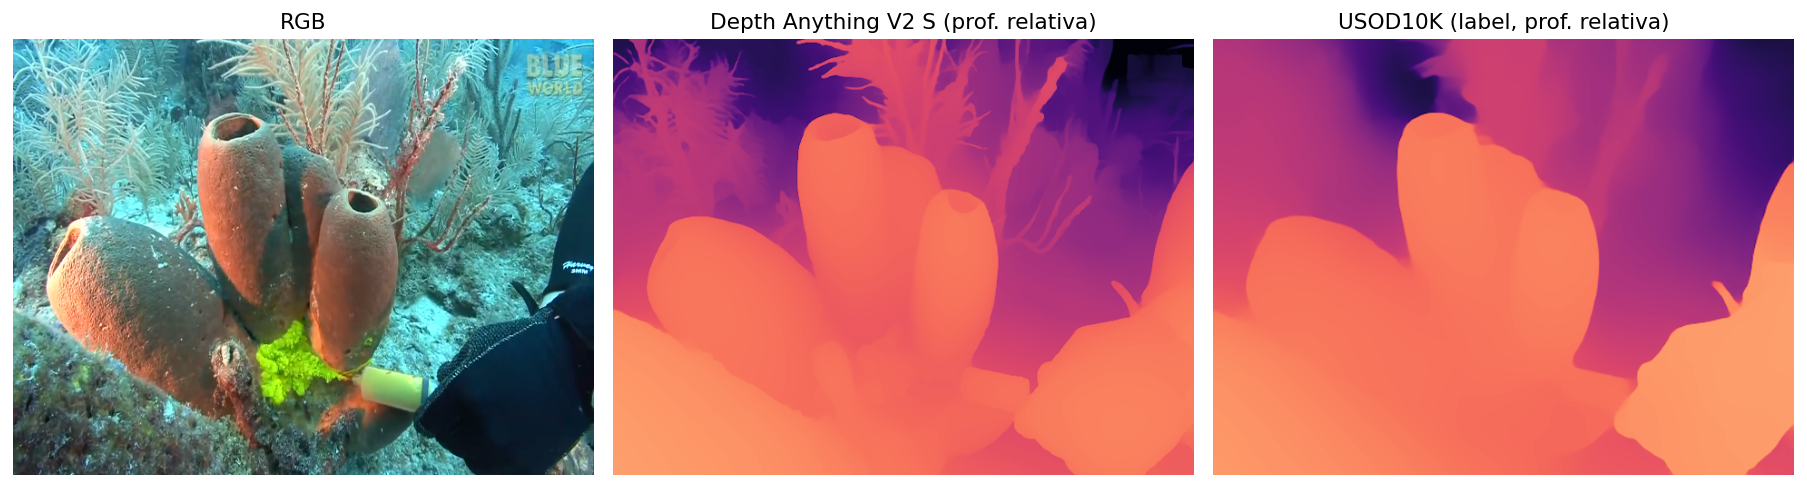

In [ ]:
import glob, numpy as np
from PIL import Image
from IPython.display import display, Image as IPImage

raw = sorted(glob.glob("preds_da_usod/raw/test/*.npy"))
rel = sorted(glob.glob("preds_da_usod/rel/test/*.png"))
print(len(raw), len(rel))                       # os dois devem ser 1026
a = np.load(raw[0]); b = np.asarray(Image.open(rel[0]))
print(a.dtype, a.shape, a.min(), a.max(), "|", b.dtype, b.shape, b.min(), b.max())

# a previsão em profundidade relativa deve ter o mesmo sentido do label (correlação positiva)
import os
cors = []
for r in rel[:200]:
    gt = np.asarray(Image.open(os.path.join("/content/usod_zip/usod10k_new_script/depth/test", os.path.basename(r))), dtype=np.float64)
    p = np.asarray(Image.open(r), dtype=np.float64)
    cors.append(np.corrcoef(p.ravel(), gt.ravel())[0, 1])
print("correlação com o label: média", np.mean(cors).round(3), "| fração positiva", np.mean(np.array(cors) > 0).round(3))

for f in sorted(glob.glob("preds_da_usod/raw/test/preview_*.png"))[:3]:
    display(IPImage(f))

In [ ]:
!cd /content/Yolo-Depth-Underwater && zip -qr preds_da_usod_test.zip preds_da_usod
!cp /content/Yolo-Depth-Underwater/preds_da_usod_test.zip /content/drive/MyDrive/DL_projeto/
!ls -la /content/drive/MyDrive/DL_projeto/preds_da_usod_test.zip

-rw------- 1 root root 1328402136 Nov 21 19:34 /content/drive/MyDrive/DL_projeto/preds_da_usod_test.zip


In [ ]:
import sys
sys.path.insert(0, "/content/Yolo-Depth-Underwater/src")

import sys, types
import numpy as np

# store_predictions.py importa o UniDepth no topo; se ele não estiver instalado (Colab), usa um stub
try:
    import unidepth  # noqa: F401
except ImportError:
    _stub = types.ModuleType("yolo_depth_underwater.unidepth_model")
    _stub.UniDepthV2Model = object
    sys.modules["yolo_depth_underwater.unidepth_model"] = _stub

from yolo_depth_underwater import inference_model
from yolo_depth_underwater.depth_anything_model import DepthAnythingV2Model


class DepthAnythingRelDepth(inference_model.InferenceModel):
    """Depth Anything V2 na convenção dos labels do USOD10K (maior = mais longe).

    disparidade -> min-max por imagem -> depth_rel = eps / (d + eps), em unidades de
    profundidade (valor_uint16 / 1000), para o store_predictions gravar o PNG uint16
    no mesmo formato dos labels convertidos. Não é metros.
    """

    def __init__(self, eps=0.25, variant="small"):
        self._model = DepthAnythingV2Model(variant=variant)
        self._eps = eps

    def predict(self, images):
        for disp in self._model.predict(images):
            disp = np.asarray(disp, dtype=np.float64)
            d = (disp - disp.min()) / max(disp.max() - disp.min(), 1e-9)
            rel = self._eps / (d + self._eps) * 65.535
            yield np.minimum(rel, 65.5349).astype(np.float32)  # evita o aviso de "acima do teto"

    def predict_split(self, split):
        raise NotImplementedError

In [ ]:
!cd /content/Yolo-Depth-Underwater && git log --oneline -5 && git branch --show-current
!grep -rn "output_kind" /content/Yolo-Depth-Underwater/src /content/Yolo-Depth-Underwater/scripts | head -20

9fb0c1b (HEAD -> flsea-eval, origin/flsea-eval) add output kind to the inference model interface
574b6df add note on absolute scal
7d58d4b add FLSea evaluation: metrics, 240-frame manifest, Depth Anything V2 wrapper
3d49d28 add load_depth function
78ce7bd fixed store predictions
flsea-eval
grep: /content/Yolo-Depth-Underwater/src/yolo_depth_underwater/__pycache__/depth_anything_model.cpython-313.pyc: binary file matches
grep: /content/Yolo-Depth-Underwater/src/yolo_depth_underwater/__pycache__/inference_model.cpython-313.pyc: binary file matches
/content/Yolo-Depth-Underwater/src/yolo_depth_underwater/depth_anything_model.py:44:    def output_kind(self) -> inference_model.OutputKind:
/content/Yolo-Depth-Underwater/src/yolo_depth_underwater/depth_anything_model.py:86:        here (see ``output_kind``), not meters."""
/content/Yolo-Depth-Underwater/src/yolo_depth_underwater/evaluation.py:4:image out) plus the ``output_kind`` property: ``DEPTH`` (farther = larger) or
/content/Yolo-Depth-U

In [ ]:
class DepthAnythingRelDepth2(DepthAnythingRelDepth):
    output_kind = "depth"

store_predictions.store_predictions(DepthAnythingRelDepth2(), ds, "preds_da_usod_all")

Starting Depth Anything V2: depth-anything/Depth-Anything-V2-Small-hf


Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 86.0±16.3 MB/s, size: 383.9 KB)
train: Scanning /content/usod_zip/usod10k_new_script/depth/train... 7178 images, 0 missing depth, 0 corrupt: 100% ━━━━━━━━━━━━ 7178/7178 261.4it/s 27.5s
train: New cache created: /content/usod_zip/usod10k_new_script/depth/train.cache
WARNING ⚠️ train: 12.3GB RAM required to cache images with 100% safety margin but only 10.6/12.7GB available, not caching images
Saving train split (7178 images) into 'preds_da_usod_all/train'


train predictions: 100%|██████████| 7178/7178 [22:29<00:00,  5.32it/s]

val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 102.2±52.1 MB/s, size: 333.3 KB)


val: Scanning /content/usod_zip/usod10k_new_script/depth/val... 2051 images, 0 missing depth, 0 corrupt: 100% ━━━━━━━━━━━━ 2051/2051 246.1it/s 8.3s
val: New cache created: /content/usod_zip/usod10k_new_script/depth/val.cache
WARNING ⚠️ cache='ram' may produce non-deterministic training results. Consider cache='disk' as a deterministic alternative if your disk space allows.
val: Caching images (1.8GB RAM): 100% ━━━━━━━━━━━━ 2051/2051 122.5it/s 16.7s
Saving val split (2051 images) into 'preds_da_usod_all/val'


val predictions: 100%|██████████| 2051/2051 [06:33<00:00,  5.21it/s]


test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 87.3±35.4 MB/s, size: 265.2 KB)
test: Scanning /content/usod_zip/usod10k_new_script/depth/test.cache... 1026 images, 0 missing depth, 0 corrupt: 100% ━━━━━━━━━━━━ 1026/1026 253.1Mit/s 0.0s
WARNING ⚠️ cache='ram' may produce non-deterministic training results. Consider cache='disk' as a deterministic alternative if your disk space allows.
test: Caching images (0.9GB RAM): 100% ━━━━━━━━━━━━ 1026/1026 96.9it/s 10.6s
Saving test split (1026 images) into 'preds_da_usod_all/test'


test predictions: 100%|██████████| 1026/1026 [03:10<00:00,  5.38it/s]


In [ ]:
import glob, os, numpy as np
from PIL import Image

base = "preds_da_usod_all"; gt_base = "/content/usod_zip/usod10k_new_script/depth"
for s, n in [("train", 7178), ("val", 2051), ("test", 1026)]:
    mine = sorted(os.path.basename(p) for p in glob.glob(f"{base}/{s}/*.png"))
    gts = sorted(os.listdir(f"{gt_base}/{s}"))
    gts = [g for g in gts if g.endswith(".png")]
    print(s, len(mine), "esperado", n, "| mesmos nomes dos labels:", mine == gts)

# o test novo deve ser igual (±1) ao que o script anterior gerou, se a pasta ainda existir
if os.path.isdir("preds_da_usod/rel/test"):
    diffs = []
    for p in sorted(glob.glob("preds_da_usod/rel/test/*.png"))[:100]:
        a = np.asarray(Image.open(p), dtype=int); b = np.asarray(Image.open(f"{base}/test/{os.path.basename(p)}"), dtype=int)
        diffs.append(np.abs(a - b).max())
    print("diferença máxima vs script anterior (100 imagens):", max(diffs))
x = np.asarray(Image.open(sorted(glob.glob(f"{base}/val/*.png"))[0]))
print(x.dtype, x.shape, x.min(), x.max())

train 7178 esperado 7178 | mesmos nomes dos labels: True
val 2051 esperado 2051 | mesmos nomes dos labels: True
test 1026 esperado 1026 | mesmos nomes dos labels: True
diferença máxima vs script anterior (100 imagens): 1
uint16 (480, 640) 13107 65535


In [ ]:
!cd /content/Yolo-Depth-Underwater && zip -qr0 preds_da_usod_all.zip preds_da_usod_all
!ls -la /content/Yolo-Depth-Underwater/preds_da_usod_all.zip
!cp /content/Yolo-Depth-Underwater/preds_da_usod_all.zip /content/drive/MyDrive/DL_projeto/
!ls -la /content/drive/MyDrive/DL_projeto/preds_da_usod_all.zip

-rw-r--r-- 1 root root 2900319328 Nov 21 20:48 /content/Yolo-Depth-Underwater/preds_da_usod_all.zip
-rw------- 1 root root 2900319328 Nov 21 20:49 /content/drive/MyDrive/DL_projeto/preds_da_usod_all.zip


#EDA do USOD e do FLSea

##EDA DO USOD

In [1]:
!ls /content/usod_zip/usod10k_new_script | head
!ls /content/Yolo-Depth-Underwater/scripts | head

ls: cannot access '/content/usod_zip/usod10k_new_script': No such file or directory
ls: cannot access '/content/Yolo-Depth-Underwater/scripts': No such file or directory


In [2]:
!pip -q install gdown
!gdown 1eJW9-EN6nTe_sKSzO6XxkoJPNwhoGBN9 -O /content/usod.zip
!unzip -q /content/usod.zip -d /content/usod_zip
!ls /content/usod_zip/usod10k_new_script

Downloading...
From (original): https://drive.google.com/uc?id=1eJW9-EN6nTe_sKSzO6XxkoJPNwhoGBN9
From (redirected): https://drive.google.com/uc?id=1eJW9-EN6nTe_sKSzO6XxkoJPNwhoGBN9&confirm=t&uuid=b9aca396-0d37-47e7-8dbe-9ddbf152a55c
To: /content/usod.zip
100% 6.02G/6.02G [01:08<00:00, 88.1MB/s]
annotations  data.yaml	depth  images


In [3]:
import os, collections
from PIL import Image

root = "/content/usod_zip/usod10k_new_script"
rows = {}
for split in ["train", "val", "test"]:
    imgs = sorted(os.listdir(f"{root}/images/{split}"))
    deps = sorted(os.listdir(f"{root}/depth/{split}"))
    sizes = collections.Counter(Image.open(f"{root}/images/{split}/{n}").size for n in imgs)   # (largura, altura); lê só o cabeçalho
    modes = collections.Counter(Image.open(f"{root}/images/{split}/{n}").mode for n in imgs[:300])
    lmodes = collections.Counter(Image.open(f"{root}/depth/{split}/{n}").mode for n in deps[:300])
    # a imagem e o label têm o mesmo tamanho?
    diff = sum(Image.open(f"{root}/images/{split}/{n}").size != Image.open(f"{root}/depth/{split}/{n}").size for n in imgs[:300])
    rows[split] = len(imgs)
    print(f"{split:5s} {len(imgs):5d} imagens | {len(deps):5d} labels | mesmos nomes: {imgs == deps}")
    print(f"      resoluções (L,A): {sizes.most_common(5)} | distintas: {len(sizes)}")
    print(f"      modo da imagem: {dict(modes)} | modo do label: {dict(lmodes)} | tamanho imagem != label (em 300): {diff}")
total = sum(rows.values()); print("total:", total, {k: f"{v/total:.1%}" for k, v in rows.items()})

train  7178 imagens |  7178 labels | mesmos nomes: True
      resoluções (L,A): [((640, 480), 7178)] | distintas: 1
      modo da imagem: {'RGB': 300} | modo do label: {'I;16': 300} | tamanho imagem != label (em 300): 0
val    2051 imagens |  2051 labels | mesmos nomes: True
      resoluções (L,A): [((640, 480), 2051)] | distintas: 1
      modo da imagem: {'RGB': 300} | modo do label: {'I;16': 300} | tamanho imagem != label (em 300): 0
test   1026 imagens |  1026 labels | mesmos nomes: True
      resoluções (L,A): [((640, 480), 1026)] | distintas: 1
      modo da imagem: {'RGB': 300} | modo do label: {'I;16': 300} | tamanho imagem != label (em 300): 0
total: 10255 {'train': '70.0%', 'val': '20.0%', 'test': '10.0%'}


#### Inventário do USOD10K
O dataset convertido tem 10.255 imagens (treino 7.178, validação 2.051, teste 1.026; 70/20/10%). Todas as imagens têm 640×480 pixels (RGB, 8 bits) e cada uma tem um label de 16 bits do mesmo tamanho e nome. A resolução é uniforme, então não há redimensionamento a tratar. Seguimos para a análise de cor.

split             R            G            B   luminância    contraste    R/G    B/G
train    74.7±41.2  113.0±38.0  113.2±47.7  101.6±32.7   32.8±14.7   0.69   1.03
val      79.8±42.1  111.7±35.4  109.8±45.5  101.9±31.4   33.8±15.0   0.74   1.01
test     76.8±42.5  113.1±36.8  114.0±46.6  102.4±32.3   33.0±14.9   0.70   1.04


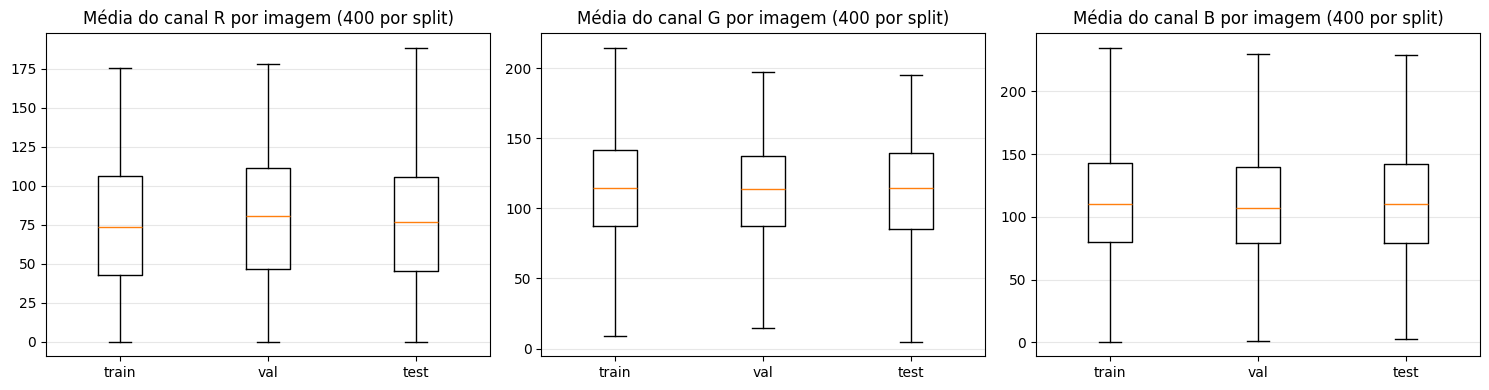

In [4]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
stats = {}
for split in ["train", "val", "test"]:
    names = sorted(os.listdir(f"{root}/images/{split}"))
    pick = rng.choice(len(names), min(400, len(names)), replace=False)
    m = []
    for i in pick:
        x = np.asarray(Image.open(f"{root}/images/{split}/{names[i]}").convert("RGB"), dtype=np.float64).reshape(-1, 3)
        lum = x @ np.array([0.299, 0.587, 0.114])
        m.append([*x.mean(0), lum.mean(), lum.std()])
    stats[split] = np.array(m)

print(f"{'split':6s} {'R':>12s} {'G':>12s} {'B':>12s} {'luminância':>12s} {'contraste':>12s} {'R/G':>6s} {'B/G':>6s}")
for s, a in stats.items():
    print(f"{s:6s} " + " ".join(f"{a[:, j].mean():6.1f}±{a[:, j].std():4.1f}" for j in range(5))
          + f" {np.mean(a[:, 0] / a[:, 1]):6.2f} {np.mean(a[:, 2] / a[:, 1]):6.2f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for k, (j, t) in enumerate([(0, "R"), (1, "G"), (2, "B")]):
    ax[k].boxplot([stats[s][:, j] for s in stats], showfliers=False)
    ax[k].set_xticklabels(list(stats))
    ax[k].set_title(f"Média do canal {t} por imagem (400 por split)")
    ax[k].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

### Estatísticas de cor (400 imagens por split)
**Medido:** média de R, G, B, luminância, contraste intra-imagem (desvio dos pixels), R/G e B/G por split.
**Observado:** R/G ≈ 0,69–0,74 (vermelho 26–31% menor que o verde); B/G ≈ 1,0. Os três splits têm valores próximos (luminância ≈ 102, contraste ≈ 33). Há grande variação entre imagens (desvio de R ≈ 41; bigodes até ≈ 0).
**Decisão:** tratar val/test como representativos do treino quanto à cor. Inspecionar as imagens extremas (passo 3). Manter augmentation de cor por canal como experimento (E4).

de 1200 imagens | R médio < 5: 51 | luminância < 20: 6 | luminância > 235: 0


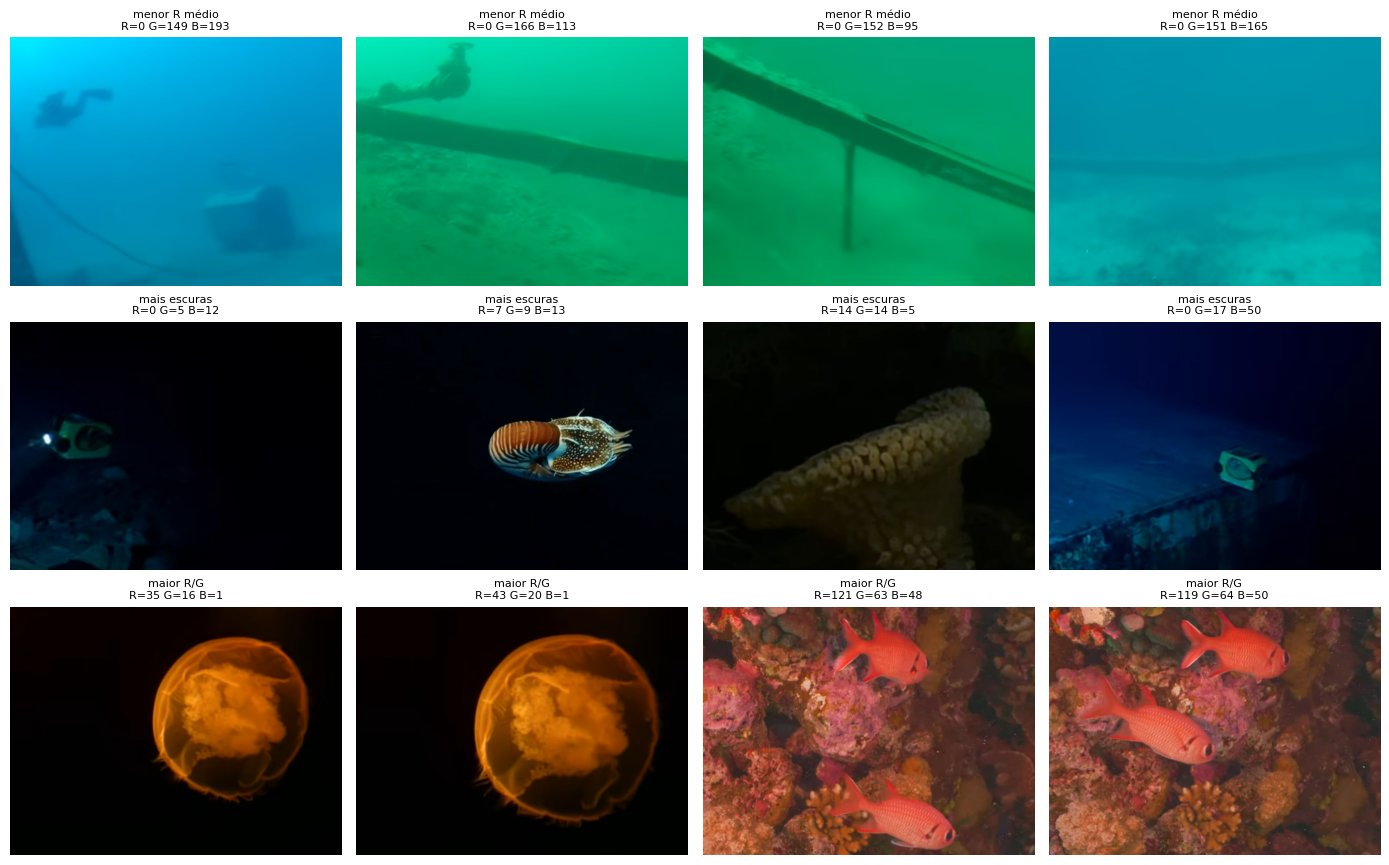

In [5]:
rng = np.random.default_rng(0)
recs = []
for split in ["train", "val", "test"]:
    names = sorted(os.listdir(f"{root}/images/{split}"))
    for i in rng.choice(len(names), min(400, len(names)), replace=False):
        x = np.asarray(Image.open(f"{root}/images/{split}/{names[i]}").convert("RGB"), dtype=np.float64).reshape(-1, 3)
        m = x.mean(0)
        recs.append((split, names[i], m[0], m[1], m[2], (x @ np.array([0.299, 0.587, 0.114])).mean()))
R, G, B, lum = (np.array([r[k] for r in recs]) for k in (2, 3, 4, 5))
print("de", len(recs), "imagens | R médio < 5:", int((R < 5).sum()), "| luminância < 20:", int((lum < 20).sum()),
      "| luminância > 235:", int((lum > 235).sum()))
groups = {"menor R médio": np.argsort(R)[:4], "mais escuras": np.argsort(lum)[:4],
          "maior R/G": np.argsort(-(R / np.maximum(G, 1e-6)))[:4]}
fig, ax = plt.subplots(3, 4, figsize=(14, 8.8))
for r, (title, idx) in enumerate(groups.items()):
    for c, i in enumerate(idx):
        ax[r, c].imshow(Image.open(f"{root}/images/{recs[i][0]}/{recs[i][1]}").convert("RGB")); ax[r, c].axis("off")
        ax[r, c].set_title(f"{title}\nR={R[i]:.0f} G={G[i]:.0f} B={B[i]:.0f}", fontsize=8)
plt.tight_layout(); plt.show()

### Imagens extremas (1200 amostradas)
**Medido:** 3 grupos: menor R médio, mais escuras, maior R/G.
**Observado:** 51/1200 (4,3%) têm R médio < 5, com canal vermelho praticamente zerado (aparência de imagem processada). 6/1200 (0,5%) têm luminância < 20 (cenas de baixa luz). Nenhuma com luminância > 235. Há cenas com luz artificial ou cores próprias dos objetos (R/G alto).
**Decisão:** manter todas as imagens. O dataset mistura águas verdes, azuis, escuras e iluminadas; relatar a fração com R≈0 como limitação e possível fonte de erro.

split           min          max    mediana/img     p5/img    p95/img  faixa cheia
train   13107-13107  65535-65535    27160±9237       15528      51071      100.0%
val     13107-13107  65535-65535    27800±9457       15420      52443      100.0%
test    13107-13107  65535-65535    27937±9554       15533      51503      100.0%


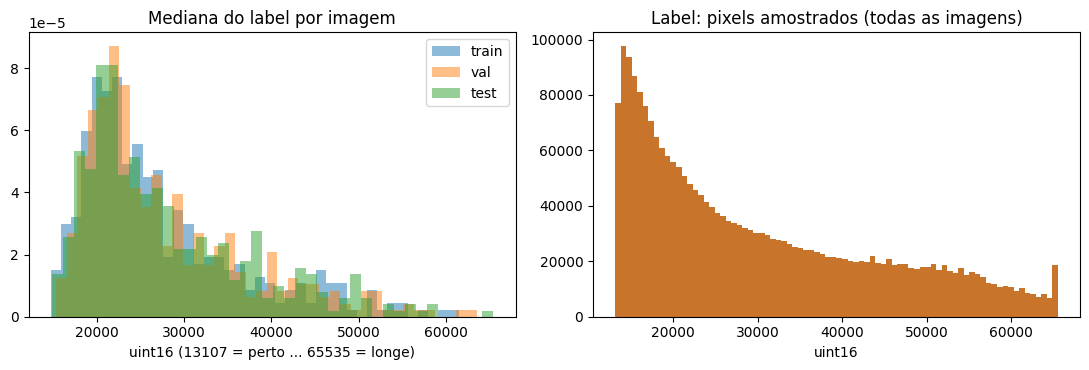

In [6]:
rng = np.random.default_rng(1)
lab = {s: [] for s in ["train", "val", "test"]}
pix = []
for split in lab:
    names = sorted(os.listdir(f"{root}/depth/{split}"))
    for i in rng.choice(len(names), min(400, len(names)), replace=False):
        a = np.asarray(Image.open(f"{root}/depth/{split}/{names[i]}"))
        lab[split].append((a.min(), a.max(), np.median(a), np.percentile(a, 5), np.percentile(a, 95)))
        pix.append(a.ravel()[rng.choice(a.size, min(2000, a.size), replace=False)])
pix = np.concatenate(pix)
print(f"{'split':6s} {'min':>12s} {'max':>12s} {'mediana/img':>14s} {'p5/img':>10s} {'p95/img':>10s} {'faixa cheia':>12s}")
for s, v in lab.items():
    v = np.array(v, dtype=float)
    full = np.mean((v[:, 0] <= 13200) & (v[:, 1] >= 65400))
    print(f"{s:6s} {v[:, 0].min():6.0f}-{v[:, 0].max():<5.0f} {v[:, 1].min():6.0f}-{v[:, 1].max():<5.0f} "
          f"{v[:, 2].mean():8.0f}±{v[:, 2].std():<5.0f} {v[:, 3].mean():10.0f} {v[:, 4].mean():10.0f} {full:11.1%}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for s, v in lab.items():
    ax[0].hist(np.array(v, dtype=float)[:, 2], bins=40, alpha=0.5, label=s, density=True)
ax[0].set_title("Mediana do label por imagem"); ax[0].set_xlabel("uint16 (13107 = perto ... 65535 = longe)"); ax[0].legend()
ax[1].hist(pix, bins=80, color="#c8742b"); ax[1].set_title("Label: pixels amostrados (todas as imagens)"); ax[1].set_xlabel("uint16")
plt.tight_layout(); plt.show()

### Estatísticas dos labels (400 por split)
**Medido:** mín, máx, mediana, p5 e p95 por imagem; fração de imagens com faixa cheia; histogramas.
**Observado:** 100% das imagens usam a faixa inteira (13107–65535) nos três splits, consequência da normalização min-max por imagem. Mediana por imagem: 27160±9237 (train), 27800±9457 (val), 27937±9554 (test); histogramas sobrepostos. Distribuição assimétrica (massa na parte "perto"), com pico no extremo "longe" (65535).
**Decisão:** splits equivalentes quanto aos labels. Como não há escala entre imagens, avaliar só com métricas alinhadas por imagem; o resultado mede concordância com o pseudo-label, não precisão métrica.

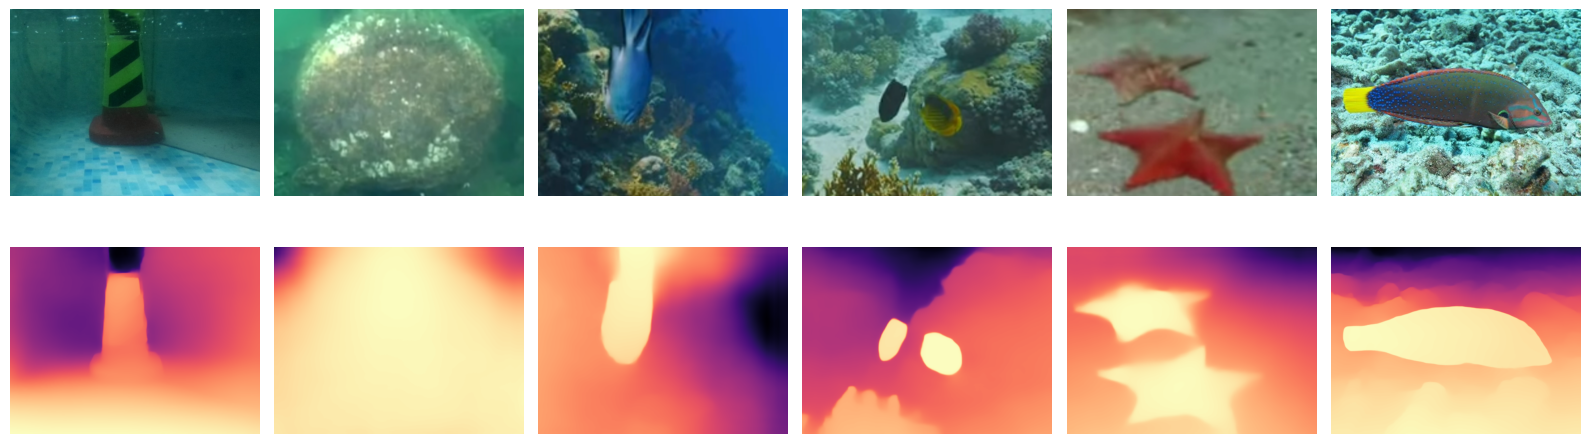

In [7]:
rng = np.random.default_rng(2)
names = sorted(os.listdir(f"{root}/images/test"))
idx = rng.choice(len(names), 6, replace=False)
fig, ax = plt.subplots(2, 6, figsize=(16, 5.5))
for c, i in enumerate(idx):
    n = names[i]
    dn = n if os.path.exists(f"{root}/depth/test/{n}") else os.path.splitext(n)[0] + ".png"
    ax[0, c].imshow(Image.open(f"{root}/images/test/{n}").convert("RGB"))
    ax[1, c].imshow(np.asarray(Image.open(f"{root}/depth/test/{dn}")), cmap="magma_r", vmin=13107, vmax=65535)
    ax[0, c].axis("off"); ax[1, c].axis("off")
plt.tight_layout(); plt.show()

O label de profundidade (cores claras = perto, escuras = longe na escala magma_r) é coerente com a cena: peixe, estrela-do-mar e pilar aparecem claros, e o fundo aberto aparece escuro. Ele é suave, em formato de "manchas", e sem bordas finas. Isso é típico de pseudo-profundidade do DPT. Na segunda imagem (rocha em close) o mapa é quase plano, então há pouca estrutura para um modelo acertar. Serve como exemplo na seção de resultados e como justificativa para não prometer precisão de borda.

###EDA DO FLSea

In [9]:
from google.colab import drive; drive.mount("/content/drive")

Mounted at /content/drive


In [11]:
import os, sys, getpass, subprocess, shutil
from pathlib import Path
# 1) código do repositório (main já tem o FLSea) + dependências
if not Path("/content/Yolo-Depth-Underwater").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/AndreFGard/Yolo-Depth-Underwater", "/content/Yolo-Depth-Underwater"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics", "kagglehub", "kaggle>=1.7", "tifffile", "imagecodecs"], check=True)
sys.path.insert(0, "/content/Yolo-Depth-Underwater/src")
# 2) credenciais do Kaggle (digite; não fica salvo no notebook)
os.environ["KAGGLE_USERNAME"] = input("KAGGLE_USERNAME: ")
os.environ["KAGGLE_KEY"] = getpass.getpass("KAGGLE_KEY: ")
from yolo_depth_underwater import flsea
frames = flsea.read_manifest("/content/Yolo-Depth-Underwater/configs/flsea_eval_frames.csv")
print(len(frames), "frames no manifesto")
frames = flsea.download_frames(frames, workers=2)   # ~480 arquivos; pode levar alguns minutos
print(len(frames), "frames baixados")
# 3) cópia com a mesma estrutura do dataset, para guardar no Drive
dst = Path("/content/flsea_eval_240")
for fr in frames:
    for src, rem in ((fr.image_path, fr.image_remote), (fr.depth_path, fr.depth_remote)):
        out = dst / rem
        out.parent.mkdir(parents=True, exist_ok=True)
        if not out.exists():
            shutil.copy(src, out)
print("copiado para", dst, "| tamanho (MB):", round(sum(p.stat().st_size for p in dst.rglob("*") if p.is_file()) / 1e6))

KAGGLE_USERNAME: TomaNSantos
KAGGLE_KEY: ··········
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
240 frames no manifesto


  0%|          | 0.00/928k [00:00<?, ?B/s]


100%|██████████| 928k/928k [00:00<00:00, 2.45MB/s]

100%|██████████| 1.02M/1.02M [00:00<00:00, 2.41MB/s]


  0%|          | 0.00/1.80M [00:00<?, ?B/s]


100%|██████████| 1.80M/1.80M [00:00<00:00, 4.08MB/s]

100%|██████████| 2.30M/2.30M [00:00<00:00, 4.55MB/s]


  0%|          | 0.00/0.98M [00:00<?, ?B/s]

... (471 outputs left out)

  0%|          | 0.00/851k [00:00<?, ?B/s]


100%|██████████| 851k/851k [00:00<00:00, 2.18MB/s]

100%|██████████| 1.63M/1.63M [00:00<00:00, 3.78MB/s]


100%|██████████| 930k/930k [00:00<00:00, 2.32MB/s]


240 frames baixados
copiado para /content/flsea_eval_240 | tamanho (MB): 671


In [12]:
!cp -r /content/flsea_eval_240 /content/drive/MyDrive/flsea_eval_240

resoluções: {(608, 968): 240}
                             n  valid   dmed   dp95    dmax   gt10   gt20     RG
seq                                                                             
canyons/flatiron            20  0.855  2.018  5.108  20.408  0.011  0.000  0.345
canyons/horse_canyon        20  0.797  1.897  3.534  15.130  0.006  0.000  0.377
canyons/tiny_canyon         20  0.737  1.553  2.492   6.414  0.000  0.000  0.393
canyons/u_canyon            20  0.901  2.416  5.798  16.390  0.008  0.000  0.350
red_sea/big_dice_loop       20  0.687  2.774  7.554  36.646  0.020  0.003  0.330
red_sea/coral_table_loop    20  0.631  2.342  6.875  18.601  0.012  0.000  0.303
red_sea/cross_pyramid_loop  20  0.721  1.854  4.700  13.871  0.001  0.000  0.323
red_sea/dice_path           20  0.765  2.373  6.080  17.434  0.014  0.000  0.358
red_sea/landward_path       20  0.673  2.080  4.910  10.775  0.000  0.000  0.337
red_sea/northeast_path      20  0.753  3.293  9.171  29.606  0.050  0.002  0.35

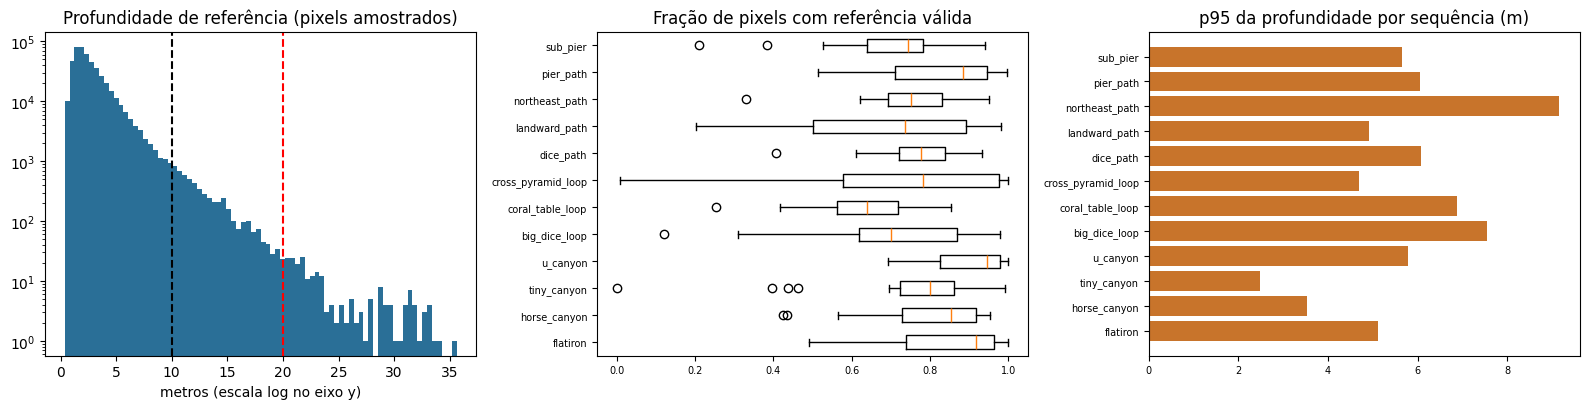

In [13]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from yolo_depth_underwater import flsea, metrics
rng = np.random.default_rng(0)
rows, pix = [], []
for fr in frames:
    img_bgr, depth = flsea.load_frame(fr)
    v = metrics.valid_mask(depth)
    d = depth[v]
    rgb = img_bgr[..., ::-1].reshape(-1, 3).astype(np.float64).mean(0)
    rows.append(dict(seq=fr.sequence, frame=fr.frame_id, h=depth.shape[0], w=depth.shape[1], valid=v.mean(),
                     dmed=np.median(d) if d.size else np.nan, dp95=np.percentile(d, 95) if d.size else np.nan,
                     dmax=d.max() if d.size else np.nan, gt10=(d > 10).mean() if d.size else np.nan,
                     gt20=(d > 20).mean() if d.size else np.nan, R=rgb[0], G=rgb[1], B=rgb[2]))
    if d.size:
        pix.append((fr.sequence, d[rng.choice(d.size, min(2000, d.size), replace=False)]))
df = pd.DataFrame(rows)
df["site"] = df.seq.str.split("/").str[0]
df["RG"] = df.R / df.G
print("resoluções:", df.groupby(["h", "w"]).size().to_dict())
g = df.groupby("seq").agg(n=("frame", "size"), valid=("valid", "mean"), dmed=("dmed", "median"), dp95=("dp95", "median"),
                          dmax=("dmax", "max"), gt10=("gt10", "mean"), gt20=("gt20", "mean"), RG=("RG", "mean")).round(3)
print(g.to_string())
alld = np.concatenate([p for _, p in pix])
print(f"\npixels amostrados: {alld.size} | mediana {np.median(alld):.2f} m | p95 {np.percentile(alld, 95):.2f} m | "
      f"> 10 m: {(alld > 10).mean():.1%} | > 20 m: {(alld > 20).mean():.1%}")
print("frames com válidos < 2%:", int((df.valid < 0.02).sum()), "| < 10%:", int((df.valid < 0.10).sum()))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].hist(alld, bins=80, color="#2a6f97"); ax[0].set_yscale("log"); ax[0].axvline(10, ls="--", c="k"); ax[0].axvline(20, ls="--", c="r")
ax[0].set_title("Profundidade de referência (pixels amostrados)"); ax[0].set_xlabel("metros (escala log no eixo y)")
order = list(g.index)
ax[1].boxplot([df[df.seq == s].valid for s in order], vert=False)
ax[1].set_yticklabels([s.split("/")[1] for s in order])
ax[1].set_title("Fração de pixels com referência válida"); ax[1].tick_params(labelsize=7)
ax[2].barh([s.split("/")[1] for s in order], g.dp95.values, color="#c8742b")
ax[2].set_title("p95 da profundidade por sequência (m)"); ax[2].tick_params(labelsize=7)
plt.tight_layout(); plt.show()

### EDA do FLSea (240 pares, 12 sequências, 20 por sequência)
**Medido:** fração de pixels com referência válida, profundidade da referência (mediana, p95, máx., frações > 10 m e > 20 m) e razão R/G por sequência.
**Observado:** todas as imagens 608×968. Profundidade mediana 2,26 m e p95 6,34 m; 1,2% dos pixels > 10 m e ~ 0,0% > 20 m. Fração válida por sequência 0,63–0,90 (cross_pyramid_loop e landward_path mais variáveis). 2 frames com < 2% de referência (descartados pelo avaliador: 238 avaliados). R/G ≈ 0,30–0,40 (USOD10K: ≈ 0,7).
**Decisão:** manter o corte de 20 m (afeta ~ 0% dos pixels). Registrar como limitações: referência SfM esparsa (~ 25% dos pixels sem valor), alcance curto (mediana ~2 m) e deslocamento de cor em relação ao USOD10K.

Leitura do EDA do FLSea

1. O corte de 20 m não afeta nada. A profundidade mediana é 2,26 m e o p95 é 6,34 m. Só 1,2% dos pixels passam de 10 m, e a fração acima de 20 m arredonda para 0,0%. O histograma confirma: depois de uns 20 m restam poucos pixels isolados (contagens de 1 a 30 por barra, escala log), provavelmente ruído da SfM. O máximo de 36,6 m em big_dice_loop vem dessa cauda. Na prática, o corte de 20 m não muda os números.

2. O FLSea é um teste de curto alcance. A mediana por sequência vai de 1,6 a 3,3 m e o p95 de 2,5 a 9,2 m. northeast_path é a sequência mais funda (p95 de 9,2 m) e tiny_canyon a mais rasa (2,5 m). Nenhuma sequência chega perto de águas abertas ou profundas.

3. Cerca de um quarto de cada imagem não tem referência. A fração válida por sequência fica entre 0,63 e 0,90. O erro é calculado só onde há referência, então regiões sem textura (areia lisa, água aberta ao fundo) tendem a ficar de fora. Declare isso como limitação do protocolo, junto com o fato de que a referência é SfM esparsa, não um sensor.

4. Duas sequências têm cobertura bem variável. cross_pyramid_loop vai de ~0,01 a ~1,0 de fração válida, e landward_path de 0,2 a 1,0. As médias por sequência dessas duas são menos confiáveis.

5. Os dois frames com menos de 2% de referência são exatamente os dois que o avaliador descartou (238 de 240). É uma verificação cruzada: o EDA e o avaliador concordam.

6. O domínio de cor é bem diferente do USOD10K. Aqui R/G fica entre 0,30 e 0,40, contra 0,69 a 0,74 no USOD. O vermelho é muito mais atenuado no FLSea, e os cânions e o Mar Vermelho ficam na mesma faixa de R/G, então a cor não separa os dois ambientes. Cuidado: calculei R/G aqui como a média das razões por frame e, no USOD, como a razão entre as médias, então o número exato não é comparável. A diferença é tão grande, porém, que a conclusão se mantém: o FLSea é um deslocamento de domínio real em relação ao USOD10K.